In [62]:
## Library Load
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [63]:
##  Step 2 Load Dataset
df=pd.read_csv("ecommerce_clean_data.csv")


In [64]:
df.head()

,OrderID,OrderDate,CustomerID,PaymentMethod,OrderStatus,CustomerName,Gender,Age,City,Region,...,Profit,ProductName,Category,CostPrice,SellingPrice,Year,Month,MonthName,YearMonth,ProfitMarginPct
0,O00001,2026-01-19,C0484,UPI,Delivered,Customer_0484,Female,31,Pune,West,...,12649.20,Mouse,Electronics,5353.0,10018.0,2026,1,January,2026-01,37.136683
1,O00001,2026-01-19,C0484,UPI,Delivered,Customer_0484,Female,31,Pune,West,...,6532.80,Shampoo,Beauty,3112.0,5568.0,2026,1,January,2026-01,41.167574
2,O00002,2026-02-14,C0450,Credit Card,Delivered,Customer_0450,Female,23,Hyderabad,South,...,3909.45,Table Lamp,Home,5905.0,10331.0,2026,2,February,2026-02,39.833613
3,O00002,2026-02-14,C0450,Credit Card,Delivered,Customer_0450,Female,23,Hyderabad,South,...,2006.80,Air Fryer,Home,3425.0,4363.0,2026,2,February,2026-02,12.776632
4,O00003,2025-11-21,C0523,Credit Card,Delivered,Customer_0523,Female,60,Delhi,North,...,4543.90,T-Shirt,Fashion,3999.0,6601.0,2025,11,November,2025-11,36.229758


In [65]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12558 entries, 0 to 12557
Data columns (total 27 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   OrderID          12558 non-null  object 
 1   OrderDate        12558 non-null  object 
 2   CustomerID       12558 non-null  object 
 3   PaymentMethod    12558 non-null  object 
 4   OrderStatus      12558 non-null  object 
 5   CustomerName     12558 non-null  object 
 6   Gender           12558 non-null  object 
 7   Age              12558 non-null  int64  
 8   City             12558 non-null  object 
 9   Region           12558 non-null  object 
 10  SignupDate       12558 non-null  object 
 11  orderDetailID    12558 non-null  object 
 12  ProductID        12558 non-null  object 
 13  Quantity         12558 non-null  int64  
 14  UnitPrice        12558 non-null  float64
 15  DiscountPct      12558 non-null  float64
 16  SalesAmount      12558 non-null  float64
 17  Profit      

In [66]:
df["OrderDate"]=pd.to_datetime(df["OrderDate"])
df["SignupDate"]=pd.to_datetime(df["SignupDate"])


In [67]:
## Step 3 -Target Define

target='Profit'

In [68]:
# Step 4 - How to understand Data Leakage 


In [69]:
# STEP 5 - Feature Select

features=[
    "Quantity",
    "UnitPrice",
    "DiscountPct",
    "Category",
    "Region",
    "PaymentMethod"]

In [70]:
# Step 6 -X and Y

X=df[features]
y=df[target]

In [71]:
X.isnull().sum()

Quantity         0
UnitPrice        0
DiscountPct      0
Category         0
Region           0
PaymentMethod    0
dtype: int64

In [72]:
y.isnull().sum()

np.int64(0)

In [73]:
# Step 8- Identity Data Type

X.dtypes

Quantity           int64
UnitPrice        float64
DiscountPct      float64
Category          object
Region            object
PaymentMethod     object
dtype: object

In [74]:
# STEP 9 - Train/Test Split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [75]:
# Step 10 - Category Column

categorical_feature=[
    "Category",
    "Region",
    "PaymentMethod"
]

numerical_features=[
    "Quantity",
    "UnitPrice",
    "DiscountPct"
]
    
    

In [76]:

 #Step 11 = One Hot Encoding
preprocessor = ColumnTransformer(
    transformers=[
        (
            'cat',
            OneHotEncoder(handle_unknown='ignore'),
            categorical_feature
        )
    ],
    remainder='passthrough'
)

In [77]:


preprocessor

,transformers,"[('cat', ...)]"
,remainder,'passthrough'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,force_int_remainder_cols,'deprecated'
,categories,'auto'
,drop,None
,sparse_output,True


In [78]:
# Step 12 - Model

from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)


In [79]:
# Step 13 -pipeline

pipeline=Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model",model)
    ]
)

In [80]:
# Step 14 - Train Model

pipeline.fit(
    X_train,
    y_train
)

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('cat', ...)]"
,remainder,'passthrough'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [81]:
# Step 15 - Predictions

y_pred=pipeline.predict(X_test)

In [82]:
y_pred

array([ 3056.532 ,  9045.083 ,   496.7665, ..., 11155.372 ,  5350.2915,
        7019.1   ], shape=(2512,))

In [83]:
# Step 16 - Actual vs Predict
comparison=pd.DataFrame({
    "Actual": y_test.values,
    "PredictedProfit": y_pred}
    )

comparison.head(10)


,Actual,PredictedProfit
0,3068.40,3056.53200
1,8642.00,9045.08300
2,502.35,496.76650
3,2876.35,2876.35000
4,1755.80,1751.57300
5,630.00,623.52150
6,-233.25,-172.29725
7,2379.80,2397.82000
8,2291.30,2303.24650
9,2184.00,2197.00000


In [84]:

# Step 17 - Model Evaluation

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("MAE :", mae)
print("MSE :", mse)
print("R2  :", r2)

MAE : 73.4593164808931
MSE : 45516.30857143378
R2  : 0.9979492010789576


In [85]:
rmse = np.sqrt(mean_squared_error(
    y_test,y_pred
)
              )
print("RMSE :", rmse)

RMSE : 213.34551453319514


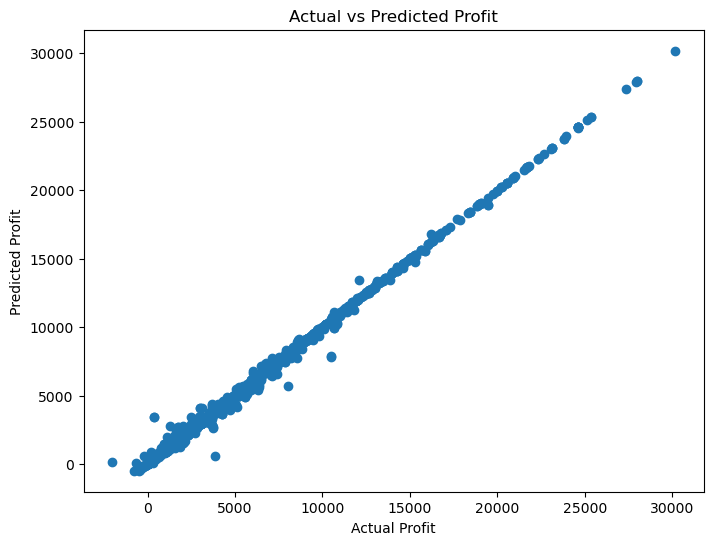

In [86]:
# Step 21 - Actual vs Predicted Visualization

plt.figure(figsize=(8,6))
plt.scatter(y_test,y_pred)
plt.xlabel('Actual Profit')
plt.ylabel('Predicted Profit')
plt.title('Actual vs Predicted Profit')
plt.show()

In [87]:
# Step 22- Residuals

residuals= y_test-y_pred
residuals.describe()

count    2512.000000
mean       -0.029081
std       213.387991
min     -3073.966000
25%       -14.669625
50%         0.000000
75%        13.703250
max      3256.270750
Name: Profit, dtype: float64

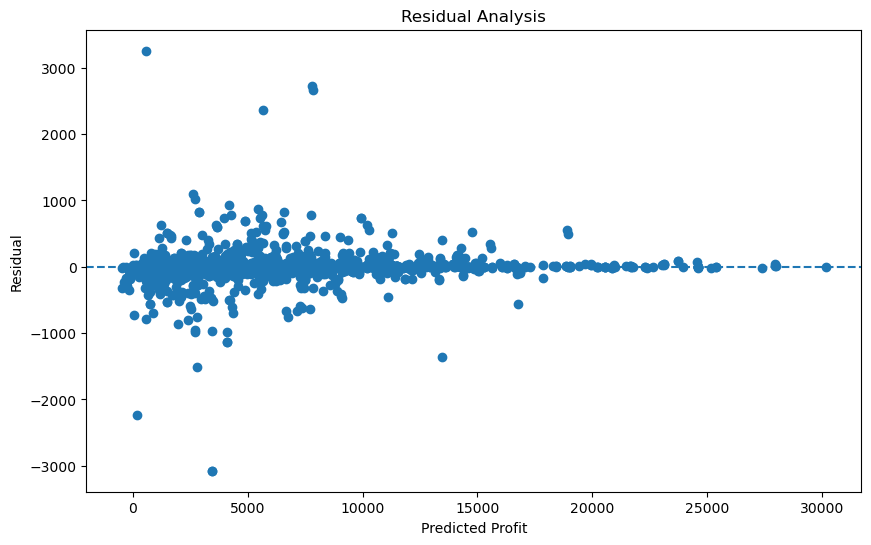

In [88]:
plt.figure(figsize=(10, 6))

plt.scatter(
    y_pred,
    residuals
)

plt.axhline(
    0,
    linestyle="--"
)

plt.xlabel("Predicted Profit")
plt.ylabel("Residual")
plt.title("Residual Analysis")

plt.show()